<a href="https://colab.research.google.com/github/lailynissaam/Analisis-Deret-Waktu/blob/main/Hands_On_STA1542_Minggu_9_Model_Musiman_dan_AUTO_ARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><center> MODEL MUSIMAN </center></h1><center>Laily Nissa A.M </center>

<center>
____________________________________________________________________________________________________________________________
</center>


Model musiman adalah model yang digunakan untuk memodelkan data-data dengan **perilaku berulang setiap periode waktu tertentu** seperti data bulanan, triwulan, harian, dan sebagainya.

Berikut contoh data musiman yaitu deret konsentrasi karbon dioksida $(CO_2)$ yang di ukur di Observatori Mauna Loa, Hawai untuk menginvestigasi perubahan atmosfer.

In [141]:
!pip install numpy==1.23.5
!pip install pmdarima

  Using cached numpy-1.23.5.tar.gz (10.7 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'numpy' when getting requirements to build wheel


In [142]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.datasets import get_rdataset
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings("ignore")

In [143]:
import statsmodels.api as sm

co2_data = sm.datasets.co2.load_pandas().data
co2 = co2_data.resample('M').mean().ffill().reset_index()
co2.columns = ['time', 'value']
co2['time'] = co2['time'].dt.year + (co2['time'].dt.month - 1) / 12.0

display(co2.head())

,time,value
0,1958.166667,316.100000
1,1958.250000,317.200000
2,1958.333333,317.433333
3,1958.416667,317.433333
4,1958.500000,315.625000


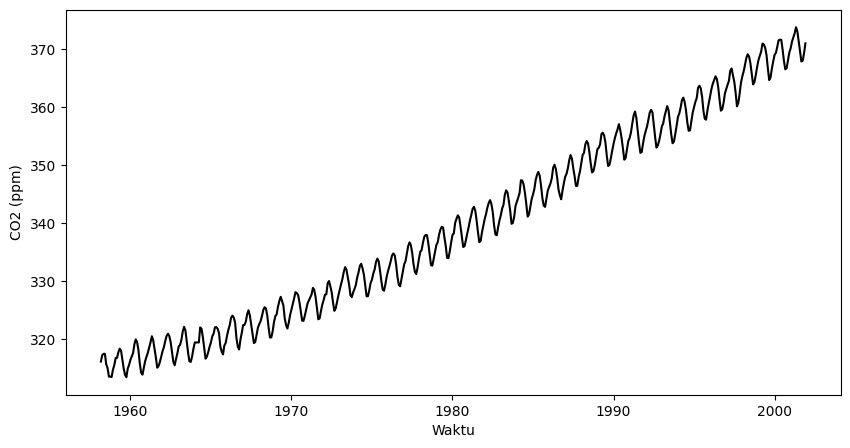

In [144]:
plt.figure(figsize=(10,5))
plt.plot(co2.time, co2.value,'-k')
plt.xlabel('Waktu'), plt.ylabel('CO2 (ppm)')
plt.show()

Tampak adanya kecenderungan naik dan perilaku berulang (kecenderungan musiman) dalam deret tersebut. Kecenderungan musiman dapat dilihat dengan lebih jelas dengan menampilkan deret untuk beberapa tahun terakhir menggunakan simbol bulanan.

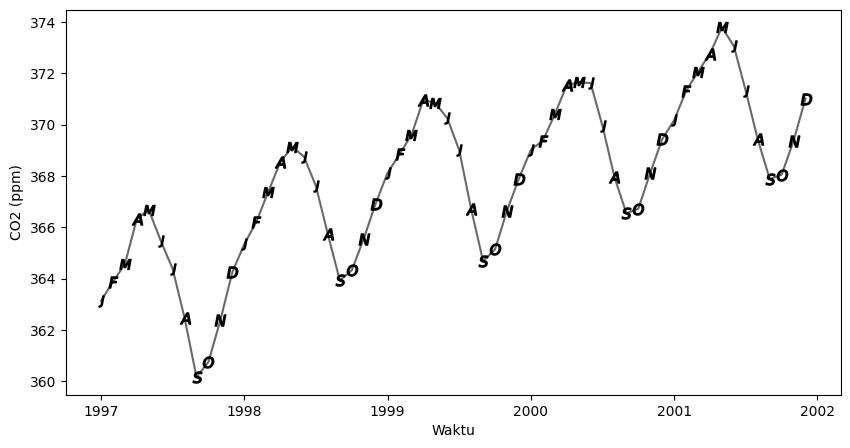

In [145]:
mapping={0:'$J$',1:'$F$',2:'$M$',3:'$A$',
         4:'$M$',5:'$J$',6:'$J$',7:'$A$',
         8:'$S$',9:'$O$',10:'$N$',11:'$D$'}
plt.figure(figsize=(10,5))
co2_new=co2[-60:].reset_index()
plt.plot(co2_new.time,co2_new.value, color='dimgray')
for i in range(len(co2_new)):
    plt.plot(co2_new.time[i], co2_new.value[i],
             marker=mapping[i%12],
             color='black', markersize=8)
plt.xlabel('Waktu'),plt.ylabel('CO2 (ppm)')
plt.show()

Dari gambar terlihat bahwa konsentrasi karbon dioksida tinggi pada bulan Maret, April, Mei, Juni, Juli dan rendah pada bulan Agustus, September, Oktober, November. Perilaku tersebut terus berulang dari tahun ke tahun.

Misalkan **$s$** menotasikan periode musiman yang diketahui, untuk deret bulanan maka 𝑠 = 12 sementara untuk deret triwulan 𝑠 = 4.

Didefinisikan model musiman **MA $(Q)$** untuk order **$Q$** dengan periode musiman **$s$** sebagai berikut:

<center> $Y_t=e_t-\Theta_1e_{t-s}-\Theta_2e_{t-2s}-...-\Theta_Qe_{t-Qs}$ </center>

Perhatikan bahwa model MA $(Q)$ musiman dapat dipandang sebagai kasus khusus dari model MA bukan musiman dengan order $q=Qs$ tetapi dengan koefisien $\theta$ semuanya bernilai nol kecuali pada lag-lag musiman $s, 2s, 3s,...,Qs$. Dapat ditunjukkan bahwa fungsi autokorelasi bernilai nol kecuali pada lag-lag musiman $s, 2s, 3s,..., Qs$ (lihat Cryer and Chan, 2008).

Model autoregressive musiman **AR $(P)$** untuk order **$P$** dengan periode musiman **$s$** juga dapat didefinisikan sebagai berikut:

<center> $Y_t=\Phi_1Y_{t-s}+\Phi_2Y_{t-2s}+...+\Phi_PY_{t-Ps}+e_t$ </center>

Model AR $(P)$ musiman dapat dipandang sebagai kasus khusus dari model AR bukan musiman dengan order $p=Ps$ tetapi dengan koefisien $\phi$ semuanya bernilai nol kecuali pada lag-lag musiman $s, 2s, 3s,...,Qs$, sehingga fungsi autokorelasi tidak nol hanya lag-lag musiman tersebut.



## Model Musiman Multiplikatif

Ide dari model musiman multiplikatif adalah mengombinakan model ARIMA musiman dan bukan musiman, sehingga diperoleh model yang memuat autokorelasi pada lag-lag musiman dan lag-lag di sekitarnya (non-musiman). Secara umum, model musiman multiplikatif ARIMA dengan periode musiman $s$ dinyatakan sebagai $ARIMA (p,d,q)\times(P,D,Q)_s$, dengan $p,d,q$ berturut-turut adalah order dari model ARIMA biasa (bukan musiman), dan $P,D,Q$ merupakan order dari ARIMA musiman.

Perhatikan bahwa dalam model ARIMA multipilkatif terdapat order $d$ dan $D$ yang msing-masing merupakan order pembedaan biasa dan pembedaan musiman. Pembedaan musiman dengan periode $s$ dari deret ${Y_t}$ dinotasikan dengan $ 𝛻_𝑠𝑌_t$ dan didefinisikan sebagai berikut:

<center> $ 𝛻_𝑠𝑌_t=Y_t-Y_{t-s}$ </center>

Suatu proses ${Y_t}$ dikatakan sebagai model musiman multiplikatif ARIMA dengan order biasa $p,d,q$ dan order musiman $P,D,Q$ serta periode musiman $s$ jika deret pembedaan:

<center> $W_t=𝛻^d𝛻^DY_t$ </center>

memenuhi model ARMA $(p,q)\times(P,Q)_s$.

Selanjutnya penentuan order $p,q$ dan $P,Q$ dapat dilakukan seperti dalam deret bukan musiman, yaitu berdasarkan plot ACF dan PACF contoh. Sebagaimana telah disebutkan bahwa fungsi autokorelasi dari deret musiman dengan periode musiman $s$ tidak bernilai nol hanya pada lag-lag kelipatan periode musiman $s$. Pola ini selanjutnya digunakan untuk menentukan order musiman $P,Q$. Sementara fungsi autokorelasi yang tidak bernilai nol pada lag selain lag-lag musiman digunakan untuk menentukan order $p,q$.

Sebagai ilustrasi digunakan deret deret konsentrasi karbon dioksida di atas, dengan periode waktu yang digunakan adalah dari tahun 1987 sampai 1997.

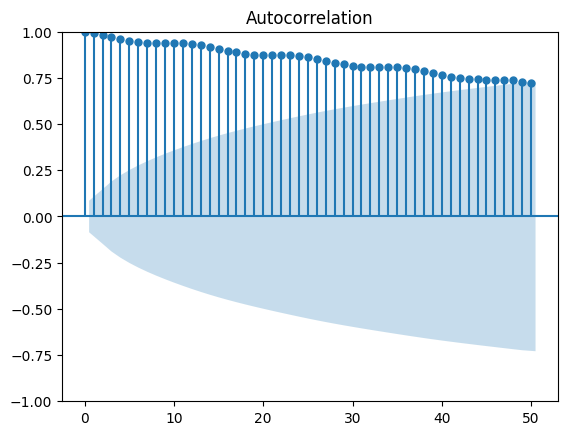

In [146]:
plot_acf(co2.value, lags=50)
plt.show()

Berdasarkan plot deret sebelumnya diketahui bahwa perilaku deret berulang setiap tahun, atau dikatakan bahwa deret memiliki periode musiman bulanan, sehingga $s=12$. Perhatikan nilai fungsi autokorelasi pada lag-lag musiman (lag 12, 24, 36,...) dalam plot ACF contoh di atas. Tampak bahwa nilai autokorelasi pada lag-lag tersebut memiliki hubungan yang kuat. Bagaimanapun juga, plot ACF contoh meluruh secara perlahan dan membentuk pola gelombang kosinus teredam, yang menandakan ketidakstasioneran (plot deret juga menunjukkan adanya trend naik dalam deret).

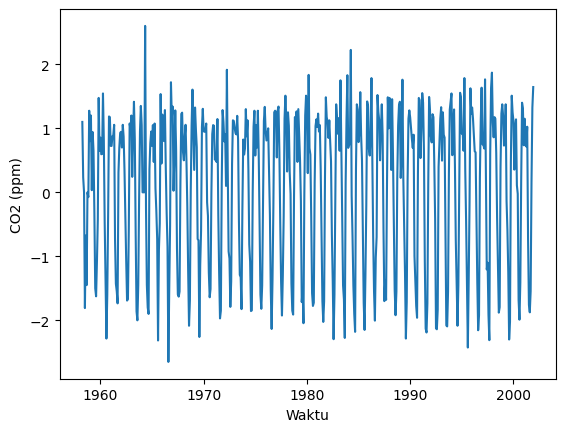

In [147]:
plt.plot(co2.time, co2.value.diff())
plt.xlabel('Waktu'), plt.ylabel('CO2 (ppm)')
plt.show()

Plot deret waktu untuk konsentrasi karbon dioksida setelah dilakukan pembedaan satu kali terhadap komponen musiman menunjukkan deret yang sudah terbebas dari efek musiman. Namun, masih terlihat bahwa deret masih belum stasioner secara umum

In [148]:
from statsmodels.tsa.stattools import adfuller

adfuller(co2.value.diff().dropna(), autolag='AIC')[1]

3.132997732390558e-05

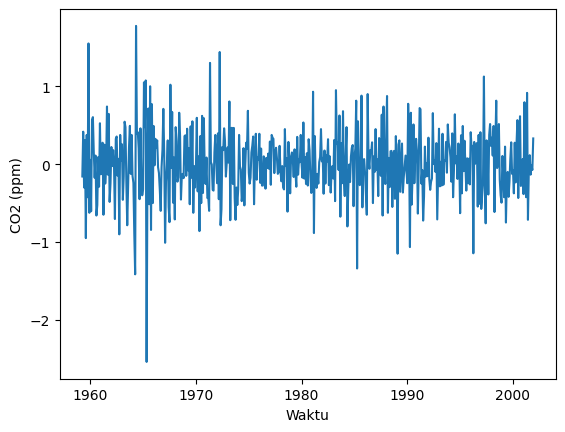

In [149]:
plt.plot(co2.time, co2.value.diff().diff(12))
plt.xlabel('Waktu'), plt.ylabel('CO2 (ppm)')
plt.show()

In [150]:
adfuller(co2.value.diff().diff(12).dropna(), autolag='AIC')[1]

3.237879279251231e-14

Setelah pembedaan musiman dan pembedaan non-musiman tampak bahwa deret sudah tidak memiliki kecenderungan apapun. Selanjutnya penentuan order $p,q$ dan $P,Q$ dapat dilakukan menggunakan plot ACF dan PACF contoh dari deret hasil pembedaan musiman dan pembedaan non-musiman tersebut.

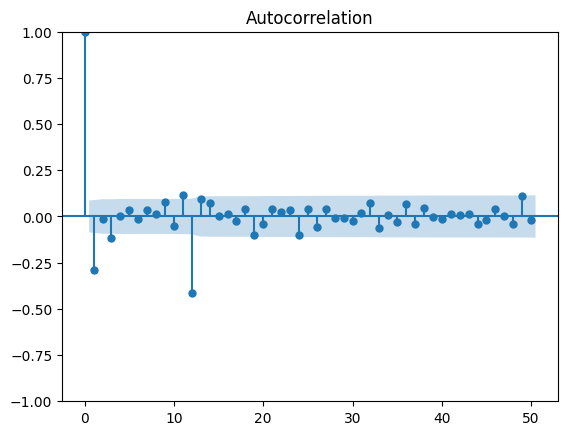

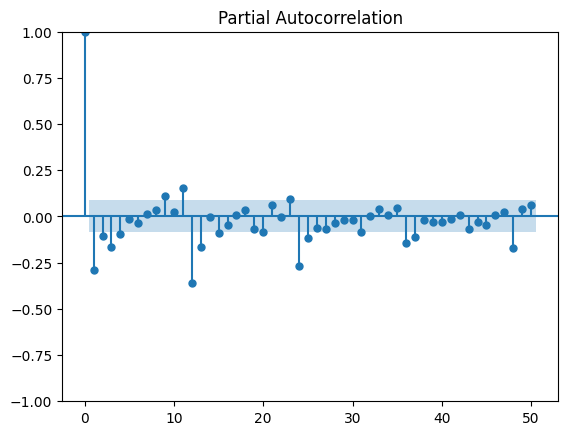

In [151]:
plot_acf(co2.value.diff().diff(12).dropna(), lags=50)
plot_pacf(co2.value.diff().diff(12).dropna(), lags=50,method='ywm')
plt.show()

Berdasarkan plot ACF contoh lag 1 signifikan sehingga dipilih order $q=1$, dan lag 12 adalah satu-satunya lag musiman yang signifikan sehingga order $Q=1$. Plot PACF contoh juga menunjukkan lag 1 dan 12 signifikan, sehingga terdapat komponen autoregressive dalam deret atau $p=1$, dan komponen musiman $P=1$. Model musiman tentatif yang dapat dipilih untuk deret konsentrasi karbon dioksida adalah $SARIMA (0,1,1)\times(0,1,1)_{12}$, $SARIMA (1,1,0)\times(1,1,0)_{12}$, $SARIMA (1,1,1)\times(1,1,1)_{12}$. Ingat kembali bahwa model yang digunakan bersifat tentatif dan dapat berubah saat diagnostik model (Model tentatif lain bisa diidentifikasi lebih jauh menggunakan EACF)

In [152]:
arima_seasonal1=ARIMA(co2.value,order=(0,1,1),
                     seasonal_order=(0,1,1,12)).fit()

arima_seasonal2=ARIMA(co2.value,order=(1,1,0),
                     seasonal_order=(1,1,0,12)).fit()

arima_seasonal3=ARIMA(co2.value,order=(1,1,1),
                     seasonal_order=(1,1,1,12)).fit()

In [153]:
print('AIC Model 1:', arima_seasonal1.aic)
print('AIC Model 2:', arima_seasonal2.aic)
print('AIC Model 3:', arima_seasonal3.aic)

AIC Model 1: 320.69374841772765
AIC Model 2: 478.91252869962113
AIC Model 3: 318.49324846428607


In [154]:
print(arima_seasonal1.summary())

                                    SARIMAX Results                                     
Dep. Variable:                            value   No. Observations:                  526
Model:             ARIMA(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -157.347
Date:                          Wed, 04 Nov 2026   AIC                            320.694
Time:                                  00:17:32   BIC                            333.415
Sample:                                       0   HQIC                           325.680
                                          - 526                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3710      0.028    -13.482      0.000      -0.425      -0.317
ma.S.L12      -0.8538      0.028    -30.560      0.

Diperoleh hasil pendugaan koefisien $\theta=0.3010$ dan $\Theta=0.7310$. Perhatikan bahwa pendugaan koefisien untuk komponen musiman pada model ini secara statistik tidak berbeda dengan nol. (Dapat dicobakan model lain sehingga diperoleh model yang terbaik.)

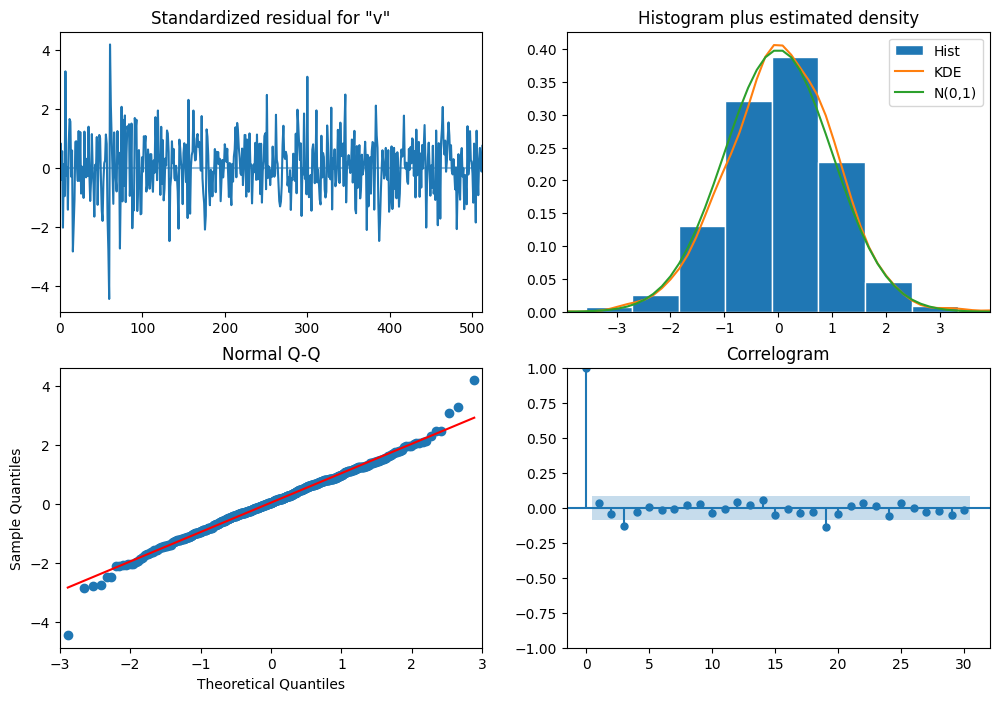

In [155]:
arima_seasonal1.plot_diagnostics(figsize=(12,8), lags=30)
plt.show()

In [156]:
arima_seasonal1.test_heteroskedasticity('breakvar')[0][1]

np.float64(0.0004961505848819082)

In [157]:
from statsmodels.stats.diagnostic import acorr_ljungbox

uji_kebebasan = acorr_ljungbox(arima_seasonal1.resid, lags=range(1,11), return_df=True)

print("Hasil Uji Kebebasan Sisaan (Ljung-Box Test):")
display(uji_kebebasan)

Hasil Uji Kebebasan Sisaan (Ljung-Box Test):


,lb_stat,lb_pvalue
1,0.001894,9.652869e-01
2,0.002021,9.989900e-01
3,0.002689,9.999630e-01
4,0.013216,9.999783e-01
5,0.013261,9.999989e-01
6,0.014564,9.999999e-01
7,0.016131,1.000000e+00
8,0.016396,1.000000e+00
9,0.023965,1.000000e+00
10,0.026267,1.000000e+00


In [158]:
from scipy.stats import shapiro
shapiro(arima_seasonal1.resid)[1]

np.float64(6.20425166825737e-45)

In [159]:
arima_seasonal4=ARIMA(co2.value,order=(0,1,1),
                     seasonal_order=(0,1,2,12)).fit()

print(arima_seasonal4.summary())

                                       SARIMAX Results                                       
Dep. Variable:                                 value   No. Observations:                  526
Model:             ARIMA(0, 1, 1)x(0, 1, [1, 2], 12)   Log Likelihood                -157.302
Date:                               Wed, 04 Nov 2026   AIC                            322.603
Time:                                       00:17:44   BIC                            339.565
Sample:                                            0   HQIC                           329.252
                                               - 526                                         
Covariance Type:                                 opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3699      0.028    -13.251      0.000      -0.425      -0.315
ma.S.L12   

In [160]:
arima_seasonal5=ARIMA(co2.value,order=(0,1,2),
                     seasonal_order=(0,1,1,12)).fit()

print(arima_seasonal5.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                  526
Model:             ARIMA(0, 1, 2)x(0, 1, [1], 12)   Log Likelihood                -155.323
Date:                            Wed, 04 Nov 2026   AIC                            318.645
Time:                                    00:17:47   BIC                            335.607
Sample:                                         0   HQIC                           325.294
                                            - 526                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3546      0.033    -10.730      0.000      -0.419      -0.290
ma.L2         -0.0851      0.044   

In [161]:
arima_seasonal6=ARIMA(co2.value,order=(0,1,1),
                     seasonal_order=(1,1,1,12)).fit()

print(arima_seasonal6.summary())

                                    SARIMAX Results                                     
Dep. Variable:                            value   No. Observations:                  526
Model:             ARIMA(0, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -157.312
Date:                          Wed, 04 Nov 2026   AIC                            322.624
Time:                                  00:17:50   BIC                            339.585
Sample:                                       0   HQIC                           329.272
                                          - 526                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3701      0.028    -13.270      0.000      -0.425      -0.315
ar.S.L12       0.0137      0.051      0.270      0.

In [162]:
arima_seasonal7=ARIMA(co2.value,order=(1,1,1),
                     seasonal_order=(0,1,1,12)).fit()

print(arima_seasonal7.summary())

                                    SARIMAX Results                                     
Dep. Variable:                            value   No. Observations:                  526
Model:             ARIMA(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -154.301
Date:                          Wed, 04 Nov 2026   AIC                            316.602
Time:                                  00:17:56   BIC                            333.563
Sample:                                       0   HQIC                           323.250
                                          - 526                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2903      0.102      2.851      0.004       0.091       0.490
ma.L1         -0.6286      0.087     -7.223      0.

Model overfitting tidak ada yang lebih baik daripada model awal. Selanjutnya model awal digunakan untuk peramalan.

In [163]:
prediksi=arima_seasonal1.get_forecast(24).summary_frame(alpha=0.05)

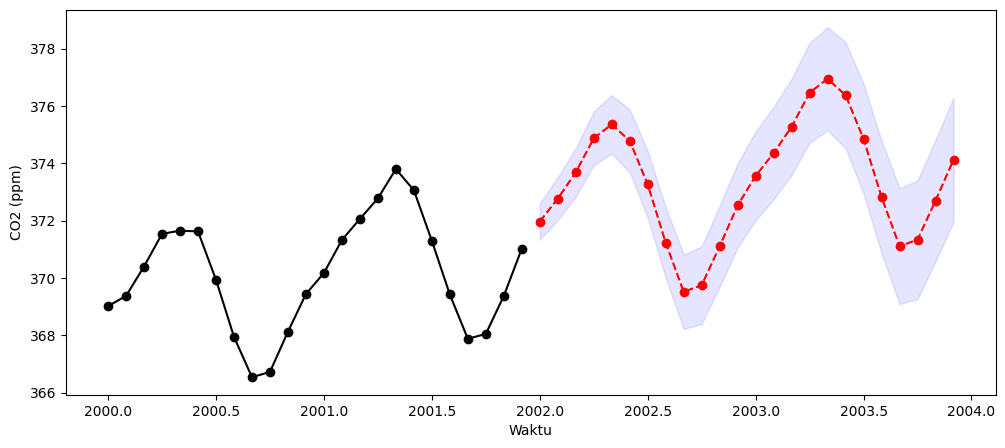

In [164]:
prediksi['time']=np.linspace(2002,2004,25)[:24]
plt.figure(figsize=(12,5))
plt.plot(co2.time[-24:],co2.value[-24:],'-ok')
plt.plot(prediksi.time,prediksi['mean'],'--or')
plt.fill_between(prediksi.time, prediksi['mean_ci_lower'],
                 prediksi['mean_ci_upper'], color='b', alpha=.1)
plt.xlabel('Waktu'), plt.ylabel('CO2 (ppm)')
plt.show()

Hasil peramalan mengikuti pola periodisitas deret dengan cukup baik. Selain itu perhatikan batas peramalan yang semakin melebar seiring meningkatnya waktu peramalan.

# AUTO-ARIMA

 **In the basic ARIMA modeling, we need to provide the p, d, and q values**. We use statistical techniques to generate these values by performing the differencing to eliminate the non-stationarity and plotting ACF and PACF graphs. Generally, the procedures of fitting an ARIMA model are as follows:

 1. Plot the data and identify any unusual observations.

 2. If necessary, transform the data (using a Box-Cox transformation) to stabilise the variance.

 3. If the data are non-stationary, take first differences of the data until the data are stationary.

 4. Examine the sample ACF and PACF of the differentiated data to determine the p and q values

 5. Try your chosen model(s) using the original data, and use the AIC to search for a better model.

 6. Check the residuals from your chosen model


 **In Auto ARIMA, the model itself will generate the optimal p, d, and q values** which would be suitable for the data to provide better forecasting.

 For illustration of Auto ARIMA, we use the real data: Global Monthly Mean Surface Air Temperature Changes Series from 1994 to 2025. It is global and hemispheric
 anomalies data.

In [165]:
url='https://raw.githubusercontent.com/lailynissaam/Analisis-Deret-Waktu/refs/heads/main/global%20surface%20land.csv'

In [166]:
climate = pd.read_csv(url)

In [167]:
climate.head()

,Date,Departure from Average
0,185001,-1.23
1,185002,-0.51
2,185003,-0.44
3,185004,-0.94
4,185005,-0.79


In [168]:
climate.Date = pd.to_datetime(climate.Date, format='%Y%m')
climate.Date = climate.Date.dt.to_period('M')

climate.head()

,Date,Departure from Average
0,1850-01,-1.23
1,1850-02,-0.51
2,1850-03,-0.44
3,1850-04,-0.94
4,1850-05,-0.79


In [169]:
climate1=climate.set_index('Date')
climate1

,Departure from Average
Date,
1850-01,-1.23
1850-02,-0.51
1850-03,-0.44
1850-04,-0.94
1850-05,-0.79
...,...
2025-08,1.45
2025-09,1.73
2025-10,1.89


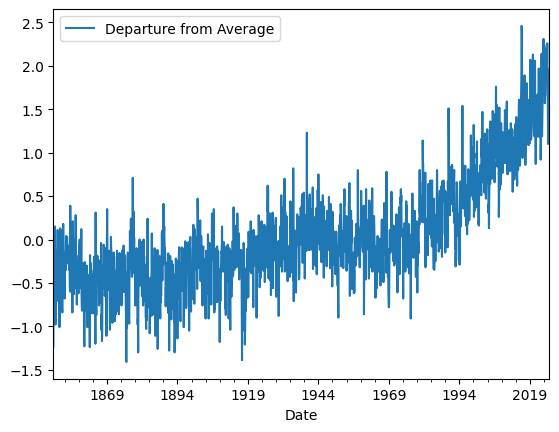

In [170]:
climate1.plot()
plt.show()

In [171]:
climate_sliced = climate1.loc["1994-01":"2025-12"]
climate_sliced = climate_sliced.to_timestamp()

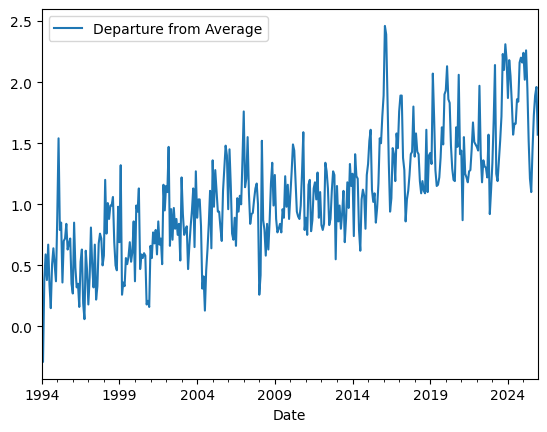

In [172]:
climate_sliced.plot()
plt.show()

Based on the time series plot above, it shows that the data is non-stationary. It can be checked by the AdFuller test.

In [173]:
from statsmodels.tsa.stattools import adfuller

adfuller(climate_sliced, autolag='AIC')[1]

0.40224899296263633

 We fit an auto ARIMA model to this data using auto_arima function from pmdarima package.

In [174]:
from pmdarima import auto_arima

 In the auto_arima function we need to provide lower and upper bounds for the p, d, and q values. Since the data does not contain a seasonal component, the
 seasonal argument is set as `False` .

In [175]:

arima_model=auto_arima(climate_sliced,
                       trace=True,
                       error_action='ignore',
                       suppress_warnings=False,
                       stepwise=True,
                       seasonal=False)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.87 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=197.401, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=157.037, Time=0.12 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=143.856, Time=0.15 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=195.447, Time=0.07 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.72 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=126.893, Time=0.26 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.87 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.81 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.10 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=126.556, Time=0.13 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=142.128, Time=0.06 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=105.624, Time=0.21 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=105.580, Time=0.16 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=155.162, Time=0.07 sec
 A

According to the `auto_arima` result, ARIMA (2,1,2) is the best model for the data.

In [176]:
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  384
Model:               SARIMAX(2, 1, 2)   Log Likelihood                 -45.508
Date:                Wed, 04 Nov 2026   AIC                            101.017
Time:                        00:18:08   BIC                            120.757
Sample:                    01-01-1994   HQIC                           108.847
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2625      0.182     -1.441      0.149      -0.619       0.094
ar.L2          0.4441      0.081      5.457      0.000       0.285       0.604
ma.L1         -0.2361      0.193     -1.222      0.2

As the model above is an optimal model, all assumptions required in model are fulfilled. To ensure that there is no violation in the assumptions, we can perform a diagnostic check.

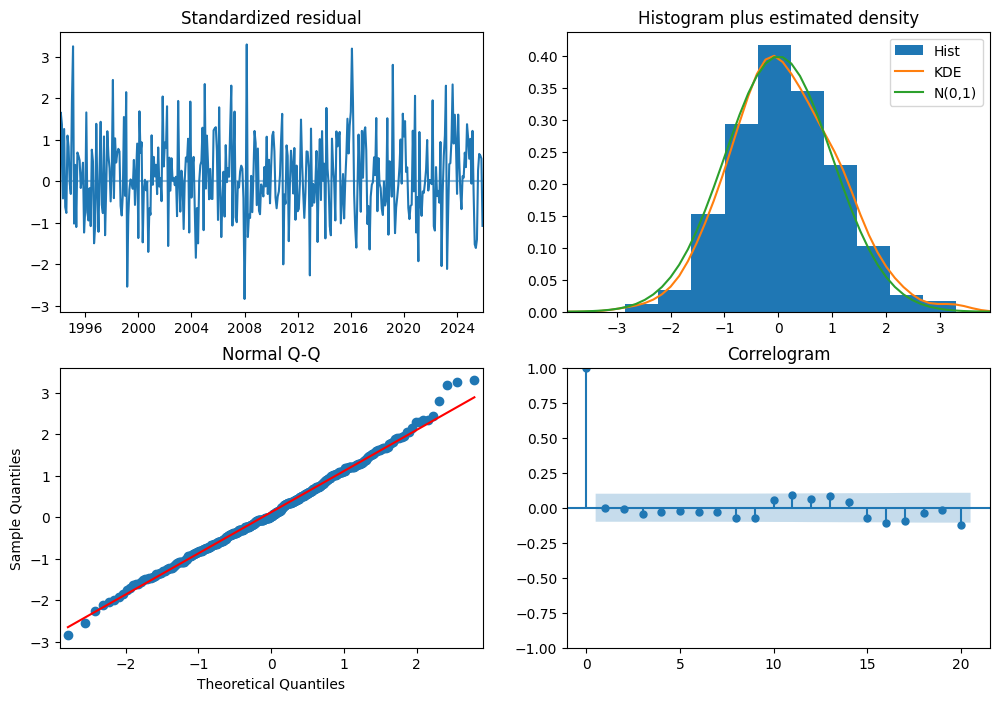

In [177]:
 arima_model.plot_diagnostics(figsize=(12,8), lags=20)
 plt.show()

In [178]:
def exog(col):
  s = []
  for i in col:
    s.append([1,i])
  return (s)

In [179]:
 from statsmodels.stats.diagnostic import het_breuschpagan
 het_breuschpagan(arima_model.resid(),exog(climate_sliced['Departure from Average']))[1]

np.float64(0.0004998696730188683)

In [180]:
 from statsmodels.sandbox.stats.runs import runstest_1samp
 runstest_1samp(arima_model.resid(), correction=False)[1]

np.float64(0.5213708468773568)

In [181]:
from scipy.stats import shapiro
shapiro(arima_model.resid())[1]

np.float64(0.40066532564646185)

There is a violation on the homogeneity test. Meanwhile, independence, and normality test of residuals provide high p-values.

In [182]:
prediksi, conf_int= arima_model.predict(20,return_conf_int=True,alpha=0.05)

In [183]:
prediksi

,0
2026-01-01,1.672527
2026-02-01,1.670363
2026-03-01,1.716467
2026-04-01,1.703403
2026-05-01,1.727310
2026-06-01,1.715232
2026-07-01,1.729020
2026-08-01,1.720036
2026-09-01,1.728518
2026-10-01,1.722302


In [184]:
conf_int=pd.DataFrame(conf_int, columns=['lower','upper']).set_index(prediksi.index)

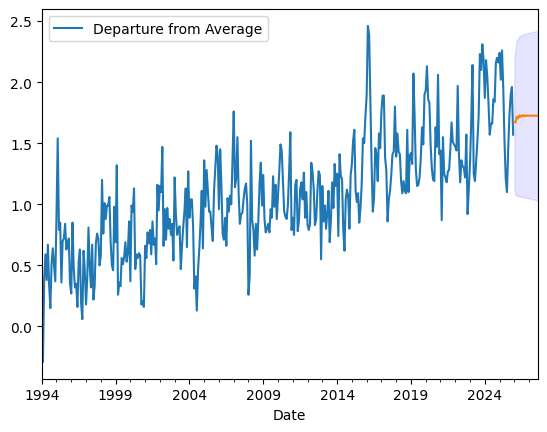

In [185]:
climate_sliced.plot()
prediksi.plot()
plt.fill_between(prediksi.index, conf_int['lower'], conf_int['upper'], color='b', alpha=.1)
plt.show()

Next, auto_arima can be used for seasonal data. In this part, we will demonstrate how to utilize auto_arima function to fit the previous dataset, which is CO2 dataset.

In [186]:
sarima_model = auto_arima(co2.value,
                          seasonal=True,
                          m=12,              # period musiman
                          trace=True,        # cetak log
                          error_action='ignore',
                          suppress_warnings=False,
                          stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=416.864, Time=4.37 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1676.811, Time=0.03 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=inf, Time=1.05 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1133.037, Time=0.67 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1678.850, Time=0.03 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=773.533, Time=3.37 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=587.512, Time=6.43 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=417.903, Time=8.86 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=404.763, Time=11.53 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=714.676, Time=10.22 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=inf, Time=11.94 sec
 ARIMA(1,1,2)(1,0,2)[12] intercept   : AIC=442.017, Time=8.84 sec
 ARIMA(2,1,1)(1,0,2)[12] intercept   : AIC=inf, Time=12.12 sec
 ARIMA(3,1,2)(1,0,2)[12] intercept   : AIC=387.472, Time=11.89 sec
 ARIMA(3,1,2)(0,0,2)[12] intercept   

In [187]:
print(sarima_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  526
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -175.780
Date:                            Wed, 04 Nov 2026   AIC                            361.559
Time:                                    00:24:42   BIC                            382.876
Sample:                                         0   HQIC                           369.906
                                            - 526                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3475      0.099      3.504      0.000       0.153       0.542
ma.L1         -0.6615      0.084   

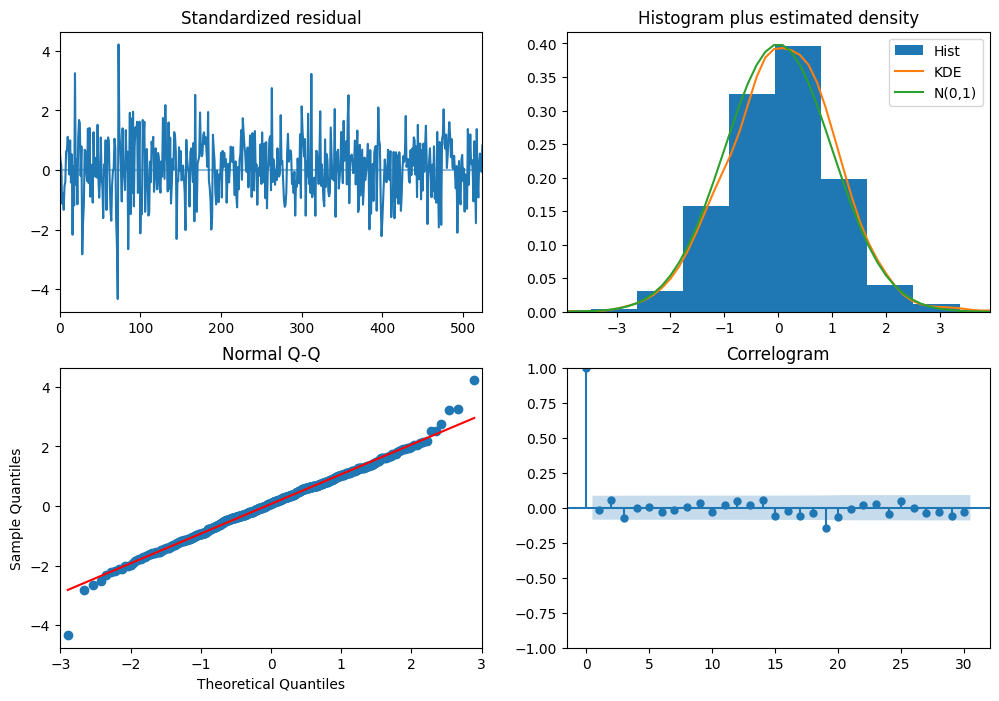

In [188]:
 sarima_model.plot_diagnostics(figsize=(12,8), lags=30)
 plt.show()

In [189]:
print(het_breuschpagan(sarima_model.resid(),exog(co2['value']))[1])

print(runstest_1samp(sarima_model.resid(), correction=False)[1])

print(shapiro(sarima_model.resid())[1])

0.16875388948139558
8.212108092742528e-05
3.397106563784288e-45


In [190]:
prediksi_seasonal, conf_int_seasonal= sarima_model.predict(24,return_conf_int=True,alpha=0.05)

In [191]:
conf_int_seasonal=pd.DataFrame(conf_int_seasonal, columns=['lower','upper']).set_index(prediksi_seasonal.index)

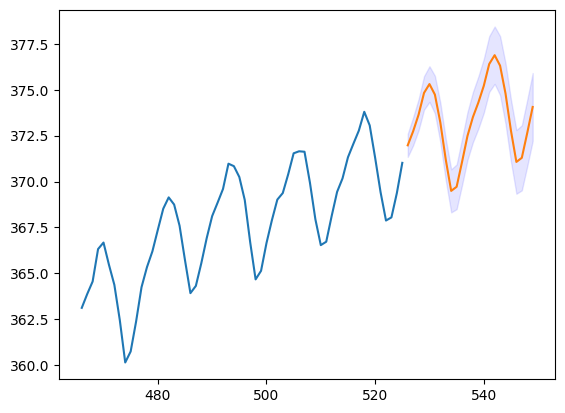

In [192]:
co2.value[-60:].plot()
prediksi_seasonal.plot()
plt.fill_between(prediksi_seasonal.index, conf_int_seasonal['lower'], conf_int_seasonal['upper'], color='b', alpha=.1)
plt.show()

**NOTE**

**In the ilustrations above, the outcomes from auto_arima appear promising. Nevertheless, it's important to remember that auto_arima does not always yield optimal results. Therefore, manual identification remains necessary.**

<center><font size='4'> TERIMAKASIH </font></center><center>_LNAM_ </center>